# Exploration: bonuses, curricula and hindsight on sparse rewards

**Code:** [`count_based_exploration.py`](../algos/count_based_exploration.py) · [`curriculum_reverse.py`](../algos/curriculum_reverse.py) · [`curriculum_size.py`](../algos/curriculum_size.py) · [`rnd.py`](../algos/rnd.py) · [`her.py`](../algos/her.py) · [`envs/bit_flip.py`](../envs/bit_flip.py) · [`experiments/curriculum_vs_exploration.py`](../experiments/curriculum_vs_exploration.py) · [`experiments/rnd_chain.py`](../experiments/rnd_chain.py)
**Papers:** Bengio 2009 ([PDF](../papers/exploration-curriculum/bengio-2009-curriculum.pdf)), Bellemare 2016 ([PDF](../papers/exploration-curriculum/bellemare-2016-count-based.pdf)), Andrychowicz 2017 HER ([PDF](../papers/exploration-curriculum/andrychowicz-2017-her.pdf)), Florensa 2017 ([PDF](../papers/exploration-curriculum/florensa-2017-reverse-curriculum.pdf)), Burda 2018 RND ([PDF](../papers/exploration-curriculum/burda-2018-rnd.pdf)) ·
**Notes:** [`papers/exploration-curriculum/notes.md`](../papers/exploration-curriculum/notes.md)

On a sparse task nothing is learned until the reward is seen once. Every method here is a way of seeing it sooner.

What you will see:

1. Why ε-greedy is not exploration: on a 30-state chain it reaches the goal with probability $2^{-29}$ per episode.
2. Where each method sends the agent, as a picture of state visits.
3. **Five methods on the same two tasks, one metric**: two curricula, a count bonus, optimistic initialisation, and ε-greedy.
4. **The bonus trap:** a bonus added to the reward inflates the values the policy is read from. Measured on the count bonus and on a one-head RND.
5. **RND with two value heads** on long chains.
6. **HER** on bit flipping: 0% for plain DQN from 10 bits, 100% with hindsight up to 20.

Sections 1, 2, 4 and part of 6 run live (about 2 minutes on CPU). The rest reads `experiments/results/exploration/`;
`python experiments/curriculum_vs_exploration.py`, `python experiments/rnd_chain.py` and `python algos/her.py` regenerate it.

In [1]:
import json, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
import torch

from algos import count_based_exploration as counts, curriculum_reverse, curriculum_size, her
from diagnostics.plots import grid_figure
from envs.bit_flip import BitFlip
from envs.chain import Chain
from envs.gridworld import GridWorld

torch.set_num_threads(1)
plt.rcParams["figure.dpi"] = 110
GAMMA = 0.99
ROOT = pathlib.Path("..") if pathlib.Path("../algos").exists() else pathlib.Path(".")
RESULTS = ROOT / "experiments/results/exploration"

## 0. The problems

**Chain(n)**: n states in a line, start at the left. "Right" moves one step; "left" sends the agent back to the start. The only reward is +1 for reaching the right end.

**GridWorld 14×14, sparse**: +1 for entering the goal corner, nothing else.

**Bit flipping (n bits)**: the state and a random goal are both n bits; each action flips one bit; reward −1 per step until the state equals the goal.

| task | states | what a random policy does |
| --- | --- | --- |
| Chain(30) | 30 | reaches the goal with probability $2^{-29} \approx 1.9 \times 10^{-9}$ per episode |
| GridWorld 14×14 | 196 | reaches the goal by chance often enough: ε-greedy solves it |
| bit flipping, 20 bits | $2^{20}$ states × $2^{20}$ goals | matches the goal with probability about $2^{-20}$ per step |

   n   P(random walk reaches goal in one episode)
   5                                     6.25e-02
  10                                     1.95e-03
  20                                     1.91e-06
  30                                     1.86e-09


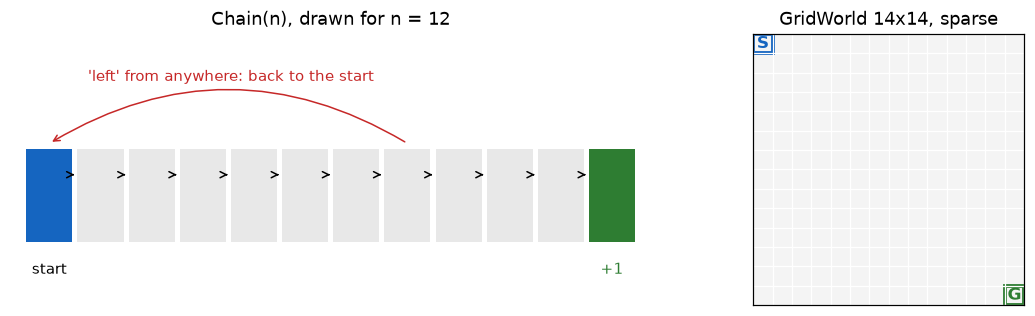

In [2]:
print(f"{'n':>4} {'P(random walk reaches goal in one episode)':>44}")
for n in (5, 10, 20, 30):
    print(f"{n:>4} {Chain(n=n).random_walk_success_probability():>44.2e}")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw=dict(width_ratios=[2.2, 1]))
ax = axs[0]; n = 12
for s in range(n):
    ax.add_patch(plt.Rectangle((s, 0), 0.9, 0.9, fc="#2e7d32" if s == n - 1 else ("#1565c0" if s == 0 else "#e8e8e8")))
    if s < n - 1:
        ax.annotate("", xy=(s + 1.0, 0.65), xytext=(s + 0.85, 0.65), arrowprops=dict(arrowstyle="->", lw=1))
ax.annotate("", xy=(0.45, 0.95), xytext=(7.45, 0.95), arrowprops=dict(arrowstyle="->", lw=1, color="#c62828", connectionstyle="arc3,rad=0.3"))
ax.text(4, 1.55, "'left' from anywhere: back to the start", color="#c62828", ha="center")
ax.text(0.45, -0.3, "start", ha="center"); ax.text(n - 0.55, -0.3, "+1", ha="center", color="#2e7d32")
ax.set_xlim(-0.3, n + 0.2); ax.set_ylim(-0.6, 2); ax.axis("off"); ax.set_title("Chain(n), drawn for n = 12")
grid_figure(GridWorld(size=14, reward_mode="sparse"), axs[1], title="GridWorld 14x14, sparse")
plt.show()

## 1. Where each method sends the agent

20,000 steps of tabular Q-learning on Chain(30), counting visits per state.
ε-greedy is the random walk until it has found something, so it stays near the start.
Optimistic initialisation (every Q starts at 1, the largest possible return) and the count bonus both make untried actions look best, so the greedy policy itself walks to the frontier.

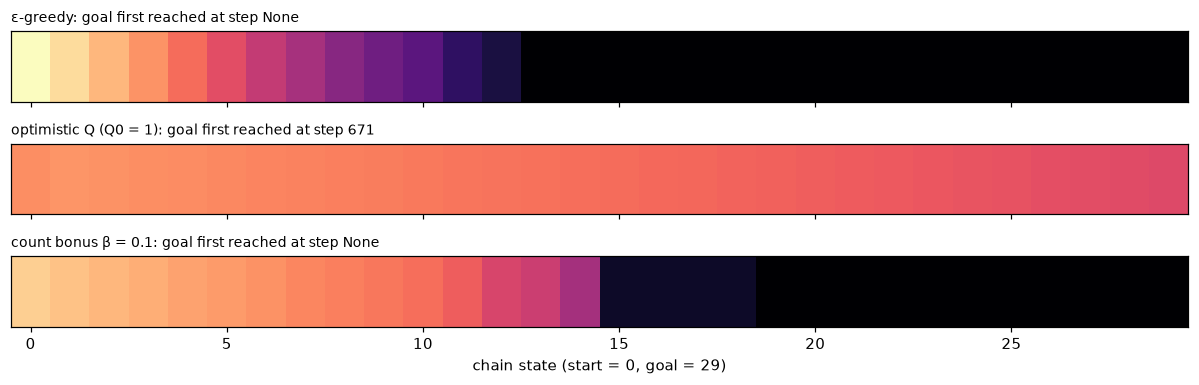

In [3]:
class Counting(Chain):
    def __init__(self, **kw):
        super().__init__(**kw); self.visits = np.zeros(self.n)
    def step(self, action):
        out = super().step(action); self.visits[self.state] += 1; return out

methods = {"ε-greedy": {}, "optimistic Q (Q0 = 1)": dict(q_init=1.0), "count bonus β = 0.1": dict(bonus=0.1)}
fig, axs = plt.subplots(len(methods), 1, figsize=(11, 3.6), sharex=True)
for ax, (name, kw) in zip(axs, methods.items()):
    env = Counting(n=30, max_steps=120)
    _, _, first = counts.train(env, n_steps=20_000, eval_every=20_000, seed=0, **kw)
    ax.imshow(np.log10(env.visits + 1)[None], aspect="auto", cmap="magma", vmin=0, vmax=4)
    ax.set_yticks([]); ax.set_title(f"{name}: goal first reached at step {first}", fontsize=9, loc="left")
axs[-1].set_xlabel("chain state (start = 0, goal = 29)"); plt.tight_layout(); plt.show()

## 2. Five methods, two tasks, one metric

Steps until the greedy policy, evaluated **exactly** from the real start, reaches 95% of the optimum. Every step counts, including the curricula's easy stages. 5 seeds, budget 200,000.

| method | how it sees the reward sooner | what it needs |
| --- | --- | --- |
| optimistic Q | untried actions look best until tried | nothing; one line |
| count bonus | $r + \beta/\sqrt{N(s,a)}$ | counts, so a finite or pseudo-counted state space |
| reverse curriculum | start next to the goal, move outward ([`curriculum_reverse.py`](../algos/curriculum_reverse.py)) | **resetting to any state** |
| size curriculum | solve a small instance, copy Q aligned at the goal ([`curriculum_size.py`](../algos/curriculum_size.py)) | **a family of tasks and a mapping between them** |

Chain(30)
       epsilon-greedy: never (0/5)
         optimistic Q: 1,300 [1,100, 1,400]
          count bonus: 72,500 [59,000, 88,000]
   reverse curriculum: 17,500 [13,000, 22,000]
      size curriculum: 850 [800, 1,200]
GridWorld 14x14
       epsilon-greedy: 23,000 [21,000, 30,300]
         optimistic Q: 20,700 [16,700, 22,100]
          count bonus: never (0/5)
   reverse curriculum: 19,000 [18,000, 23,500]
      size curriculum: 1,400 [1,200, 1,550]


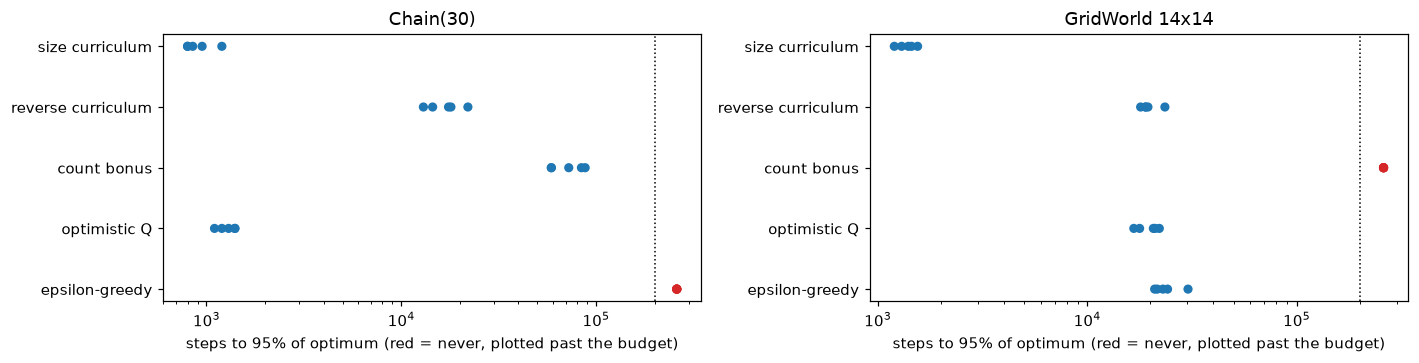

In [4]:
data = json.loads((RESULTS / "curriculum_vs_exploration.json").read_text())
methods = ["epsilon-greedy", "optimistic Q", "count bonus", "reverse curriculum", "size curriculum"]
fig, axs = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, task in zip(axs, data["table"]):
    print(task)
    for i, m in enumerate(methods):
        hits = data["table"][task][m]
        found = [h for h in hits if h is not None]
        label = f"{int(np.median(found)):,} [{min(found):,}, {max(found):,}]" if len(found) >= 3 else f"never ({len(found)}/5)"
        print(f"  {m:>19}: {label}")
        ax.scatter([h if h is not None else data['budget'] * 1.3 for h in hits], [i] * len(hits), s=25,
                   c=["tab:blue" if h is not None else "tab:red" for h in hits])
    ax.set_xscale("log"); ax.set_yticks(range(len(methods)), methods); ax.set_title(task)
    ax.axvline(data["budget"], color="k", ls=":", lw=1); ax.set_xlabel("steps to 95% of optimum (red = never, plotted past the budget)")
plt.tight_layout(); plt.show()

- **Chain(30):** ε-greedy never solves it. The size curriculum (850) and optimistic Q (1,300) are fastest, then the reverse curriculum (17,500) and the count bonus (72,500).
- **GridWorld 14×14:** ε-greedy is fine here (23,000). The size curriculum is still fastest (1,400). The count bonus **never** finishes, which section 3 explains.
- The cheapest method, optimistic initialisation, is as good as anything that needs no extra machinery. Most tutorials skip it.
- The size curriculum's lead depends on an unusually easy transfer: every cell of a chain or an open grid looks alike relative to the goal.

## 3. The bonus trap

A bonus added to the reward becomes part of what Q estimates. The greedy policy then optimises goal **plus** bonus, and Q at the start can exceed any achievable return.
Measured on the count bonus (β = 0.1, 200,000 steps on the 14×14 grid), then with the same table trained 20,000 more steps with the bonus switched off.

(6 s)  goal first reached at step 87583
max Q at the start: 1.198   exact optimal value: 0.778
greedy return during the bonus run: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
after 20,000 more steps with the bonus off: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


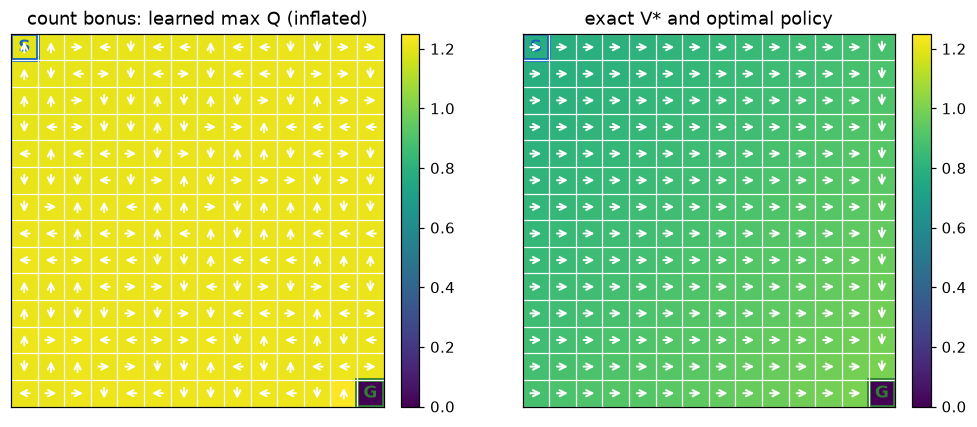

In [5]:
grid = GridWorld(size=14, reward_mode="sparse", max_steps=300)
optimal = grid.optimal_return(GAMMA)
t0 = time.time()
Q, curve, first = counts.train(grid, n_steps=200_000, bonus=0.1, eval_every=10_000, seed=0)
Q_off, curve_off, _ = counts.train(grid, n_steps=20_000, bonus=0.0, eval_every=2_000, seed=100, Q=Q)
print(f"({time.time() - t0:.0f} s)  goal first reached at step {first}")
start = grid.index(grid.start)
print(f"max Q at the start: {Q[start].max():.3f}   exact optimal value: {optimal:.3f}")
print(f"greedy return during the bonus run: {[round(v, 3) for _, v in curve[::4]]}")
print(f"after 20,000 more steps with the bonus off: {[round(v, 3) for _, v in curve_off]}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
grid_figure(grid, axs[0], values=Q.max(1), policy=Q, title="count bonus: learned max Q (inflated)")
grid_figure(grid, axs[1], values=grid.true_v(GAMMA), policy=grid.optimal_policy(GAMMA), title="exact V* and optimal policy")
for ax in axs: ax.images[0].set_clim(0, 1.25)
plt.show()

The left map is above 1 almost everywhere, though no return here can exceed 1: those are bonus values, and the arrows chase them.
Switching the bonus off does not repair it within 20,000 steps; values that high decay slowly.

The same thing happened to RND written the obvious way, with one value head and the bonus added to the reward.
On Chain(20) it ended with a greedy return of 0 on 4 of 5 seeds, its Q flat at about 1.438 for both actions in every state, above the largest achievable return of 1.0.
Fading the bonus and recomputing it per batch did not help. The fix is the paper's design: a second value head.

## 4. RND with two value heads

`algos/rnd.py`: a fixed random network $f$ and a predictor $\hat f$; novelty $\lVert \hat f(s') - f(s')\rVert^2$, normalised.
The extrinsic head $Q_E$ learns the task reward; the intrinsic head $Q_I$ learns the novelty and ignores episode ends.
The agent acts on $Q_E + \beta Q_I$; the policy that is evaluated is $Q_E$ alone, so the bonus never enters it.
Chain(20) and Chain(30), one-hot observations, 50,000 steps, 5 seeds.

Chain(20)        DQN: first goal [None, 6629, 7553, 3750, 9155]; greedy policy optimal at the end on 4/5
Chain(20)  DQN + RND: first goal [3510, 2369, 2687, 2765, 4023]; greedy policy optimal at the end on 5/5
Chain(30)        DQN: first goal [15692, 20237, 28132, 36877, None]; greedy policy optimal at the end on 2/5
Chain(30)  DQN + RND: first goal [4295, 4026, 3923, 4059, 4030]; greedy policy optimal at the end on 5/5


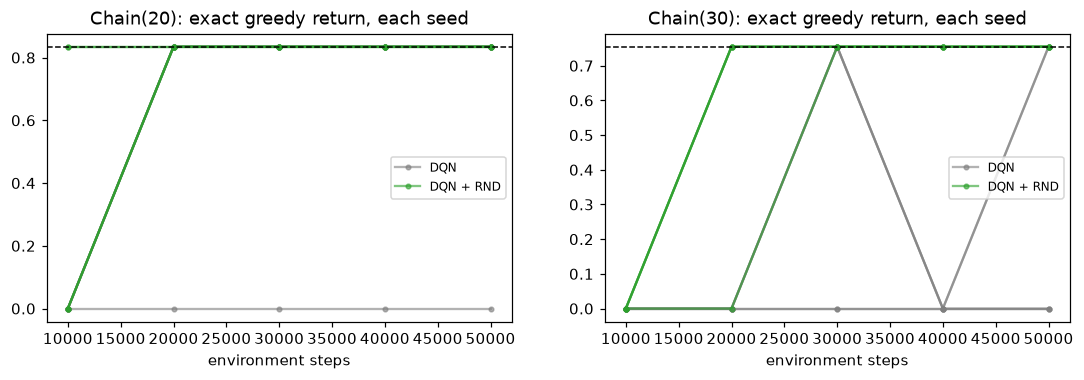

In [6]:
rows = [json.loads(p.read_text()) for p in sorted(RESULTS.glob("rnd_chain__*.json"))]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, n in zip(axs, (20, 30)):
    for name, colour in (("DQN", "tab:grey"), ("DQN + RND", "tab:green")):
        sel = [r for r in rows if r["n"] == n and r["name"] == name]
        firsts = [r["first_goal"] for r in sel]
        optimal_end = sum(r["log"][-1]["score"] >= 0.95 * r["optimum"] for r in sel)
        print(f"Chain({n}) {name:>10}: first goal {firsts}; greedy policy optimal at the end on {optimal_end}/{len(sel)}")
        for r in sel:
            ax.plot([e["step"] for e in r["log"]], [e["score"] for e in r["log"]], "o-", color=colour, alpha=0.6, ms=3,
                    label=name if r is sel[0] else None)
    ax.axhline(sel[0]["optimum"], color="k", ls="--", lw=1); ax.set_title(f"Chain({n}): exact greedy return, each seed")
    ax.set_xlabel("environment steps"); ax.legend(fontsize=8)
plt.show()

RND finds the goal sooner and ends with the optimal policy on every seed.
Plain DQN's successes on a chain where a random walk succeeds with probability $2^{-19}$ or less are not exploration.
HYPOTHESIS (unverified): the fresh network happens to prefer "right" in most states, and once ε is small it walks straight to the goal.

## 5. Hindsight Experience Replay

A failed bit-flipping episode still reached *some* state. HER stores each transition 4 more times, with the goal replaced by a state reached later in the episode and the reward recomputed ([`algos/her.py:70-77`](../algos/her.py)).
Some of those copies are successes, so the goal-conditioned network gets signal from the first episode.

First live, 10 bits, 1,000 episodes each:

(26 s)


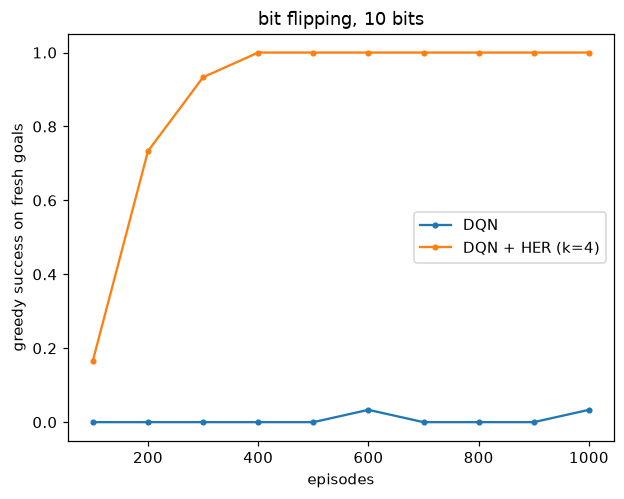

In [7]:
make = lambda: BitFlip(10)
t0 = time.time()
live = {k: her.train(make(), n_episodes=1_000, k=k, evaluate=her.success_rate(make, episodes=30), eval_every=100, seed=0)[1]
        for k in (0, 4)}
print(f"({time.time() - t0:.0f} s)")
for k, log in live.items():
    plt.plot([r["episode"] for r in log], [r["success"] for r in log], "o-", ms=3, label="DQN" if k == 0 else "DQN + HER (k=4)")
plt.xlabel("episodes"); plt.ylabel("greedy success on fresh goals"); plt.title("bit flipping, 10 bits"); plt.legend(); plt.show()

Then the full sweep from `python algos/her.py`, 4,000 episodes, 5 to 20 bits:

 bits    DQN  DQN + HER
    5   100%       100%
   10     0%       100%
   15     0%       100%
   20     0%       100%


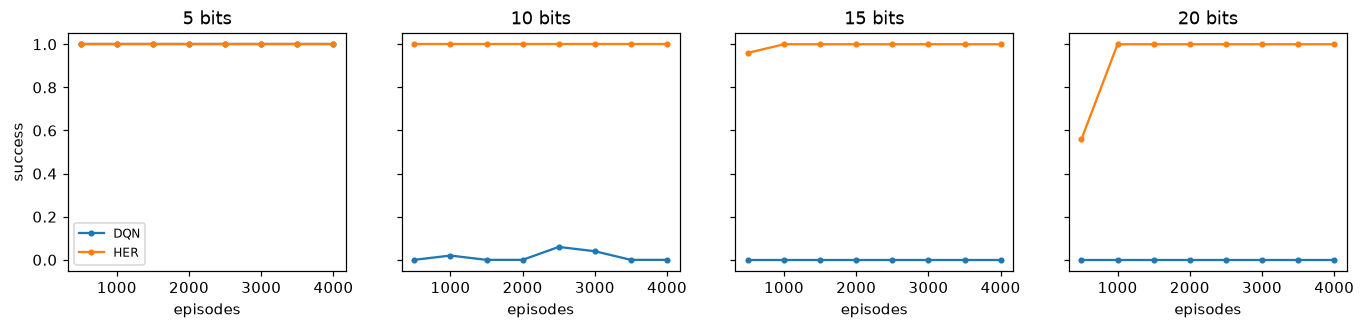

In [8]:
sweep = json.loads((RESULTS / "her_bits.json").read_text())
print(f"{'bits':>5} {'DQN':>6} {'DQN + HER':>10}")
for n in (5, 10, 15, 20):
    print(f"{n:>5} {sweep[f'{n} bits, k=0'][-1]['success']:>6.0%} {sweep[f'{n} bits, k=4'][-1]['success']:>10.0%}")
fig, axs = plt.subplots(1, 4, figsize=(15, 2.8), sharey=True)
for ax, n in zip(axs, (5, 10, 15, 20)):
    for k, label in ((0, "DQN"), (4, "HER")):
        log = sweep[f"{n} bits, k={k}"]
        ax.plot([r["episode"] for r in log], [r["success"] for r in log], "o-", ms=3, label=label)
    ax.set_title(f"{n} bits"); ax.set_xlabel("episodes")
axs[0].set_ylabel("success"); axs[0].legend(fontsize=8); plt.show()

## 6. What breaks, and how you would know

| method | symptom | likely cause |
| --- | --- | --- |
| count bonus | Q above any achievable return, greedy policy wanders | the bonus is in the reward and has not decayed (section 3) |
| count bonus | stops trying an action in a well-visited state | counting states instead of (state, action) pairs |
| optimistic Q | very slow to settle | initial value set far above the best return; set it just above |
| RND | finds the goal, then the greedy policy fails | bonus mixed into the one value head; use two heads (section 4) |
| RND | bonus constant from the start | predictor too large or learning too fast; it fits everything immediately |
| HER | no better than DQN | relabelled copies keep the old reward; it must be recomputed for the new goal |
| HER | relabelled goals from before the transition | "future" means a state reached at or after t |
| reverse curriculum | start radius stops growing | success threshold out of reach at this ε and chunk size |
| size curriculum | a stage takes as long as from scratch | the transfer map is misaligned with the goal |